In [90]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline 
import pandas as pd 
from sklearn.model_selection import train_test_split 
import tensorflow as tf 
from keras.layers import Dense,LSTM,GRU
from keras.models import Sequential 
import os 
import pickle 
from sklearn.feature_selection import SelectKBest,f_classif
from sklearn.preprocessing import StandardScaler,LabelEncoder
from keras.callbacks import EarlyStopping,ModelCheckpoint
import joblib


In [38]:
data = pd.read_csv("data.csv\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv")

In [39]:
data.columns = data.columns.str.replace(" ","")

In [96]:
data.tail()

,DestinationPort,FlowDuration,TotalFwdPackets,TotalBackwardPackets,TotalLengthofFwdPackets,TotalLengthofBwdPackets,FwdPacketLengthMax,FwdPacketLengthMin,FwdPacketLengthMean,FwdPacketLengthStd,...,min_seg_size_forward,ActiveMean,ActiveStd,ActiveMax,ActiveMin,IdleMean,IdleStd,IdleMax,IdleMin,Label
225740,61374,61,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225741,61378,72,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225742,61375,75,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225743,61323,48,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
225744,61326,68,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


In [40]:
data["Label"].value_counts()

DDoS      128027
BENIGN     97718
Name: Label, dtype: int64

In [92]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 79 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   DestinationPort          225745 non-null  int64  
 1   FlowDuration             225745 non-null  int64  
 2   TotalFwdPackets          225745 non-null  int64  
 3   TotalBackwardPackets     225745 non-null  int64  
 4   TotalLengthofFwdPackets  225745 non-null  int64  
 5   TotalLengthofBwdPackets  225745 non-null  int64  
 6   FwdPacketLengthMax       225745 non-null  int64  
 7   FwdPacketLengthMin       225745 non-null  int64  
 8   FwdPacketLengthMean      225745 non-null  float64
 9   FwdPacketLengthStd       225745 non-null  float64
 10  BwdPacketLengthMax       225745 non-null  int64  
 11  BwdPacketLengthMin       225745 non-null  int64  
 12  BwdPacketLengthMean      225745 non-null  float64
 13  BwdPacketLengthStd       225745 non-null  float64
 14  Flow

In [41]:
X = data.drop("Label",axis=1)

In [42]:
y = data["Label"]

In [43]:
X.replace(to_replace=[np.inf,-np.inf],value=np.nan,inplace=True)
X.fillna(value=X.mean(),inplace=True)

In [44]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [45]:
K = 30
selector = SelectKBest(score_func=f_classif,k=K)

X_selector = selector.fit_transform(X_scaled,y)

selected_features = X.columns[selector.get_support()]

c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:112: UserWarning: Features [31 32 33 49 56 57 58 59 60 61] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\feature_selection\_univariate_selection.py:113: RuntimeWarning: invalid value encountered in true_divide
  f = msb / msw


In [46]:
df_select = pd.DataFrame(data=X_selector,columns=selected_features)

In [47]:
df_select['Label'] = y

In [95]:
df_select.to_csv("scaled.csv")

In [49]:
df_select.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 225745 entries, 0 to 225744
Data columns (total 31 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   DestinationPort          225745 non-null  float64
 1   TotalLengthofFwdPackets  225745 non-null  float64
 2   FwdPacketLengthMax       225745 non-null  float64
 3   FwdPacketLengthMin       225745 non-null  float64
 4   FwdPacketLengthMean      225745 non-null  float64
 5   FwdPacketLengthStd       225745 non-null  float64
 6   BwdPacketLengthMax       225745 non-null  float64
 7   BwdPacketLengthMin       225745 non-null  float64
 8   BwdPacketLengthMean      225745 non-null  float64
 9   BwdPacketLengthStd       225745 non-null  float64
 10  FlowPackets/s            225745 non-null  float64
 11  BwdIATTotal              225745 non-null  float64
 12  BwdIATMean               225745 non-null  float64
 13  BwdIATStd                225745 non-null  float64
 14  BwdI

In [50]:
df_select.corr()

,DestinationPort,TotalLengthofFwdPackets,FwdPacketLengthMax,FwdPacketLengthMin,FwdPacketLengthMean,FwdPacketLengthStd,BwdPacketLengthMax,BwdPacketLengthMin,BwdPacketLengthMean,BwdPacketLengthStd,...,PacketLengthVariance,SYNFlagCount,PSHFlagCount,URGFlagCount,Down/UpRatio,AveragePacketSize,AvgFwdSegmentSize,AvgBwdSegmentSize,SubflowFwdBytes,min_seg_size_forward
DestinationPort,1.000000,0.553843,0.604586,0.207158,0.658346,0.586255,-0.327077,-0.119517,-0.351014,-0.315009,...,-0.059698,0.267683,-0.185002,0.750934,0.441595,-0.080744,0.658346,-0.351014,0.553843,-0.074278
TotalLengthofFwdPackets,0.553843,1.000000,0.852427,0.004453,0.858439,0.839139,-0.184076,-0.073738,-0.199152,-0.184303,...,0.120163,0.125113,0.045338,0.317221,-0.049214,0.163564,0.858439,-0.199152,1.000000,-0.048262
FwdPacketLengthMax,0.604586,0.852427,1.000000,0.041021,0.940954,0.991672,-0.194168,-0.076854,-0.209415,-0.189367,...,0.196112,0.130111,0.034412,0.354549,-0.029093,0.182947,0.940954,-0.209415,0.852427,-0.074322
FwdPacketLengthMin,0.207158,0.004453,0.041021,1.000000,0.277425,-0.045823,-0.124594,0.033618,-0.131073,-0.120963,...,-0.103268,0.642479,-0.125592,0.282352,0.378518,-0.066908,0.277425,-0.131073,0.004453,-0.000325
FwdPacketLengthMean,0.658346,0.858439,0.940954,0.277425,1.000000,0.919632,-0.221994,-0.067832,-0.238341,-0.214916,...,0.142406,0.296502,-0.004109,0.426718,0.060985,0.168880,1.000000,-0.238341,0.858439,-0.077440
FwdPacketLengthStd,0.586255,0.839139,0.991672,-0.045823,0.919632,1.000000,-0.182455,-0.078285,-0.196846,-0.176954,...,0.211973,0.070389,0.042259,0.328437,-0.060207,0.191474,0.919632,-0.196846,0.839139,-0.075503
BwdPacketLengthMax,-0.327077,-0.184076,-0.194168,-0.124594,-0.221994,-0.182455,1.000000,-0.229004,0.961442,0.992683,...,0.854687,-0.134223,0.572493,-0.297731,-0.056924,0.832586,-0.221994,0.961442,-0.184076,-0.232879
BwdPacketLengthMin,-0.119517,-0.073738,-0.076854,0.033618,-0.067832,-0.078285,-0.229004,1.000000,-0.212724,-0.234635,...,-0.217873,-0.030968,-0.237431,-0.107997,-0.006576,-0.236391,-0.067832,-0.212724,-0.073738,0.343618
BwdPacketLengthMean,-0.351014,-0.199152,-0.209415,-0.131073,-0.238341,-0.196846,0.961442,-0.212724,1.000000,0.956006,...,0.781317,-0.143294,0.599341,-0.319591,-0.045139,0.869990,-0.238341,1.000000,-0.199152,-0.238532
BwdPacketLengthStd,-0.315009,-0.184303,-0.189367,-0.120963,-0.214916,-0.176954,0.992683,-0.234635,0.956006,1.000000,...,0.874558,-0.130118,0.553871,-0.286792,-0.061252,0.823943,-0.214916,0.956006,-0.184303,-0.234919


In [51]:
df_select.describe()

,DestinationPort,TotalLengthofFwdPackets,FwdPacketLengthMax,FwdPacketLengthMin,FwdPacketLengthMean,FwdPacketLengthStd,BwdPacketLengthMax,BwdPacketLengthMin,BwdPacketLengthMean,BwdPacketLengthStd,...,PacketLengthVariance,SYNFlagCount,PSHFlagCount,URGFlagCount,Down/UpRatio,AveragePacketSize,AvgFwdSegmentSize,AvgBwdSegmentSize,SubflowFwdBytes,min_seg_size_forward
count,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,...,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05,2.257450e+05
mean,1.070166e-16,3.021644e-18,-1.158297e-17,-1.951478e-17,-8.460603e-17,4.532466e-17,2.417315e-17,-2.014429e-17,-1.047503e-16,-4.431745e-17,...,-9.467818e-17,1.309379e-17,-1.072684e-16,3.323808e-17,1.007215e-17,-2.457604e-16,-8.460603e-17,-6.043288e-18,3.021644e-18,-4.310879e-16
std,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,...,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00,1.000002e+00
min,-4.494962e-01,-2.891194e-01,-2.888946e-01,-1.707174e-01,-3.264595e-01,-2.695068e-01,-7.383266e-01,-3.311930e-01,-7.948933e-01,-7.097708e-01,...,-6.778308e-01,-1.853781e-01,-7.356739e-01,-4.047320e-01,-7.029887e-01,-9.177026e-01,-3.264595e-01,-7.948933e-01,-2.891194e-01,-5.155709e+00
25%,-4.454465e-01,-2.811179e-01,-2.856760e-01,-1.707174e-01,-3.145757e-01,-2.695068e-01,-7.383266e-01,-3.311930e-01,-7.948933e-01,-7.097708e-01,...,-6.778308e-01,-1.853781e-01,-7.356739e-01,-4.047320e-01,-7.029887e-01,-9.057236e-01,-3.145757e-01,-7.948933e-01,-2.811179e-01,-3.558501e-01
50%,-4.454465e-01,-2.798869e-01,-2.781658e-01,-1.707174e-01,-3.092941e-01,-2.628578e-01,-7.116068e-01,-3.311930e-01,-7.127741e-01,-7.083575e-01,...,-6.720665e-01,-1.853781e-01,-7.356739e-01,-4.047320e-01,-4.068225e-03,-6.924971e-01,-3.092941e-01,-7.127741e-01,-2.798869e-01,-3.558501e-01
75%,-4.454465e-01,-2.697311e-01,-2.706555e-01,-1.339806e-01,-2.630795e-01,-2.566361e-01,8.378727e-01,-2.123352e-01,9.318417e-01,6.962046e-01,...,4.263842e-01,-1.853781e-01,1.359298e+00,-4.047320e-01,-4.068225e-03,1.145705e+00,-2.630795e-01,9.318417e-01,-2.697311e-01,-3.558501e-01
max,2.867806e+00,5.603273e+01,5.976780e+00,8.842054e+00,7.332607e+00,8.123479e+00,2.414072e+00,2.859089e+01,4.382634e+00,4.018289e+00,...,4.764436e+00,5.394380e+00,1.359298e+00,2.470771e+00,4.189455e+00,3.120024e+00,7.332607e+00,4.382634e+00,5.603273e+01,7.323923e+00


In [52]:
X = df_select.drop("Label",axis=1)

In [53]:
y = df_select["Label"]

In [55]:
le = LabelEncoder()
y = le.fit_transform(y)

In [63]:
batch_size = 32

In [58]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20)

In [59]:
X_train_lstm= X_train.values.reshape(X_train.shape[0],1,X_train.shape[1])
X_test_lstm = X_test.values.reshape(X_test.shape[0],1,X_test.shape[1])

In [74]:
model = Sequential()

model.add(LSTM(units=128,return_sequences=True,input_shape=(1,X_train.shape[1])))
model.add(LSTM(units=64,return_sequences=False))
model.add(Dense(units=32,activation='relu'))
model.add(Dense(len(le.classes_),activation="softmax"))

model.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_2 (LSTM)               (None, 1, 128)            81408     
                                                                 
 lstm_3 (LSTM)               (None, 64)                49408     
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 2)                 66        
                                                                 
Total params: 132,962
Trainable params: 132,962
Non-trainable params: 0
_________________________________________________________________


In [75]:
model.compile(loss='sparse_categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [76]:
steps = np.ceil(X_train.shape[0]/batch_size)

In [77]:
es = EarlyStopping(monitor='val_loss',patience=5,verbose=1)
mc = ModelCheckpoint(filepath='model.h5',monitor='val_loss',verbose=1,save_best_only=True)


In [79]:
history = model.fit(X_train_lstm,validation_data=(X_test_lstm,y_test),batch_size=batch_size,steps_per_epoch=steps,epochs=10)

Epoch 1/10
5644/5644 [==============================] - 36s 6ms/step - loss: 0.0296 - accuracy: 0.9934 - val_loss: 0.0308 - val_accuracy: 0.9930
Epoch 2/10
5644/5644 [==============================] - 50s 9ms/step - loss: 0.0289 - accuracy: 0.9936 - val_loss: 0.0292 - val_accuracy: 0.9932
Epoch 3/10
5644/5644 [==============================] - 52s 9ms/step - loss: 0.0286 - accuracy: 0.9936 - val_loss: 0.0312 - val_accuracy: 0.9931
Epoch 4/10
5644/5644 [==============================] - 53s 9ms/step - loss: 0.0281 - accuracy: 0.9937 - val_loss: 0.0288 - val_accuracy: 0.9932
Epoch 5/10
5644/5644 [==============================] - 42s 7ms/step - loss: 0.0282 - accuracy: 0.9937 - val_loss: 0.0300 - val_accuracy: 0.9930
Epoch 6/10
5644/5644 [==============================] - 45s 8ms/step - loss: 0.0281 - accuracy: 0.9937 - val_loss: 0.0299 - val_accuracy: 0.9932
Epoch 7/10
5644/5644 [==============================] - 49s 9ms/step - loss: 0.0281 - accuracy: 0.9936 - val_loss: 0.0298 - val_ac

In [81]:
va_acc,va_loss = model.evaluate(X_test_lstm,y_test)
print(va_acc*100)
print(va_loss*100)

1411/1411 [==============================] - 5s 3ms/step - loss: 0.0285 - accuracy: 0.9935
2.8522953391075134
99.3510365486145


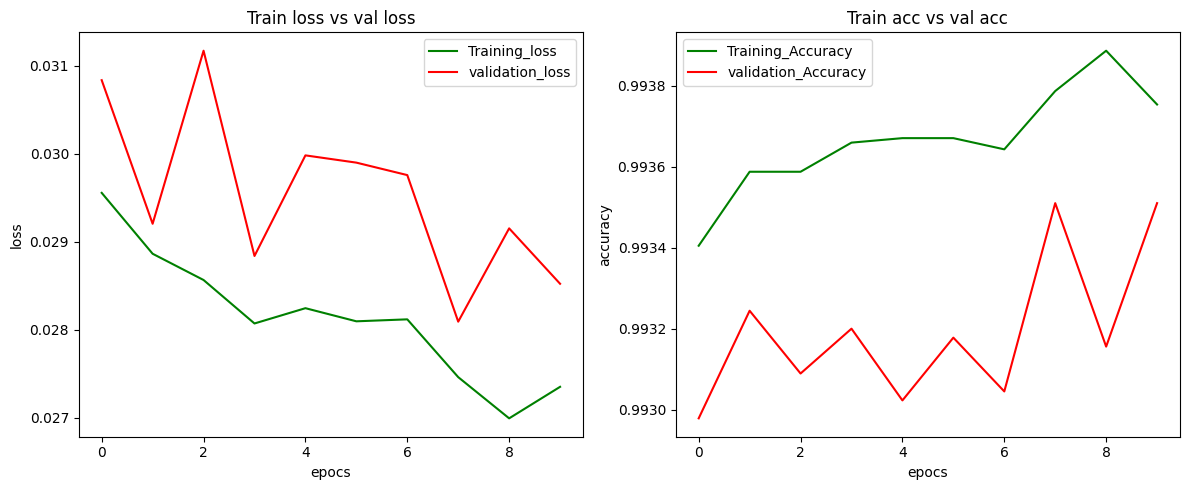

In [86]:
fig,ax = plt.subplots(1,2,figsize=(12,5))

ax[0].plot(history.history["loss"],label="Training_loss",color="green")
ax[0].plot(history.history["val_loss"],label="validation_loss",color='red')
ax[0].legend(frameon=True)
ax[0].set_xlabel("epocs")
ax[0].set_ylabel("loss")
ax[0].set_title("Train loss vs val loss")

ax[1].plot(history.history["accuracy"],label="Training_Accuracy",color="green")
ax[1].plot(history.history["val_accuracy"],label="validation_Accuracy",color='red')
ax[1].legend(frameon=True)
ax[1].set_xlabel("epocs")
ax[1].set_ylabel("accuracy")
ax[1].set_title("Train acc vs val acc")

plt.tight_layout()
plt.show()


In [87]:
model.save("model.h5")

In [91]:
joblib.dump(scaler,"scaler.pkl")

['scaler.pkl']